# Lab Exercise 8

A store is visited by $n$ customers in a day. The number $Y$ of customers who buy a product is

$$Y \mid n \sim \text{Binomial}(n, \theta), \qquad n \sim \text{Poisson}(10),$$

where $\theta$ (the probability that a customer buys) is **known**. The unknown quantity is $n$.

We compute the posterior $p(n \mid Y)$ for every combination of $Y \in \{0, 5, 10\}$ and $\theta \in \{0.2, 0.5\}$.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az



## 1. The PyMC model


- **Prior:** `n = pm.Poisson("n", mu=10)`
- **Likelihood:** `y = pm.Binomial("y", n=n, p=theta, observed=Y)`



In [7]:
Y_values = [0, 5, 10]
theta_values = [0.2, 0.5]

def fit_model(Y, theta, seed=42):
    with pm.Model() as model:
        n = pm.Poisson("n", mu=10)                              # prior
        y = pm.Binomial("y", n=n, p=theta, observed=Y)          # likelihood
        idata = pm.sample(draws=4000, tune=1000, chains=4,
                          random_seed=seed, progressbar=False)
    return idata

results = {}
for Y in Y_values:
    for theta in theta_values:
        results[(Y, theta)] = fit_model(Y, theta)
        print(f"done: Y={Y}, theta={theta}")

Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 1 seconds.


done: Y=0, theta=0.2


Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 1 seconds.


done: Y=0, theta=0.5


Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 1 seconds.


done: Y=5, theta=0.2


... (2 outputs left out)

Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 1 seconds.


done: Y=10, theta=0.2


Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 1 seconds.


done: Y=10, theta=0.5


## 2. Visualizing all the posteriors in one figure

Rows are the values of $Y$, columns the values of $\theta$. The vertical reference line marks the prior mean $E[n] = 10$.

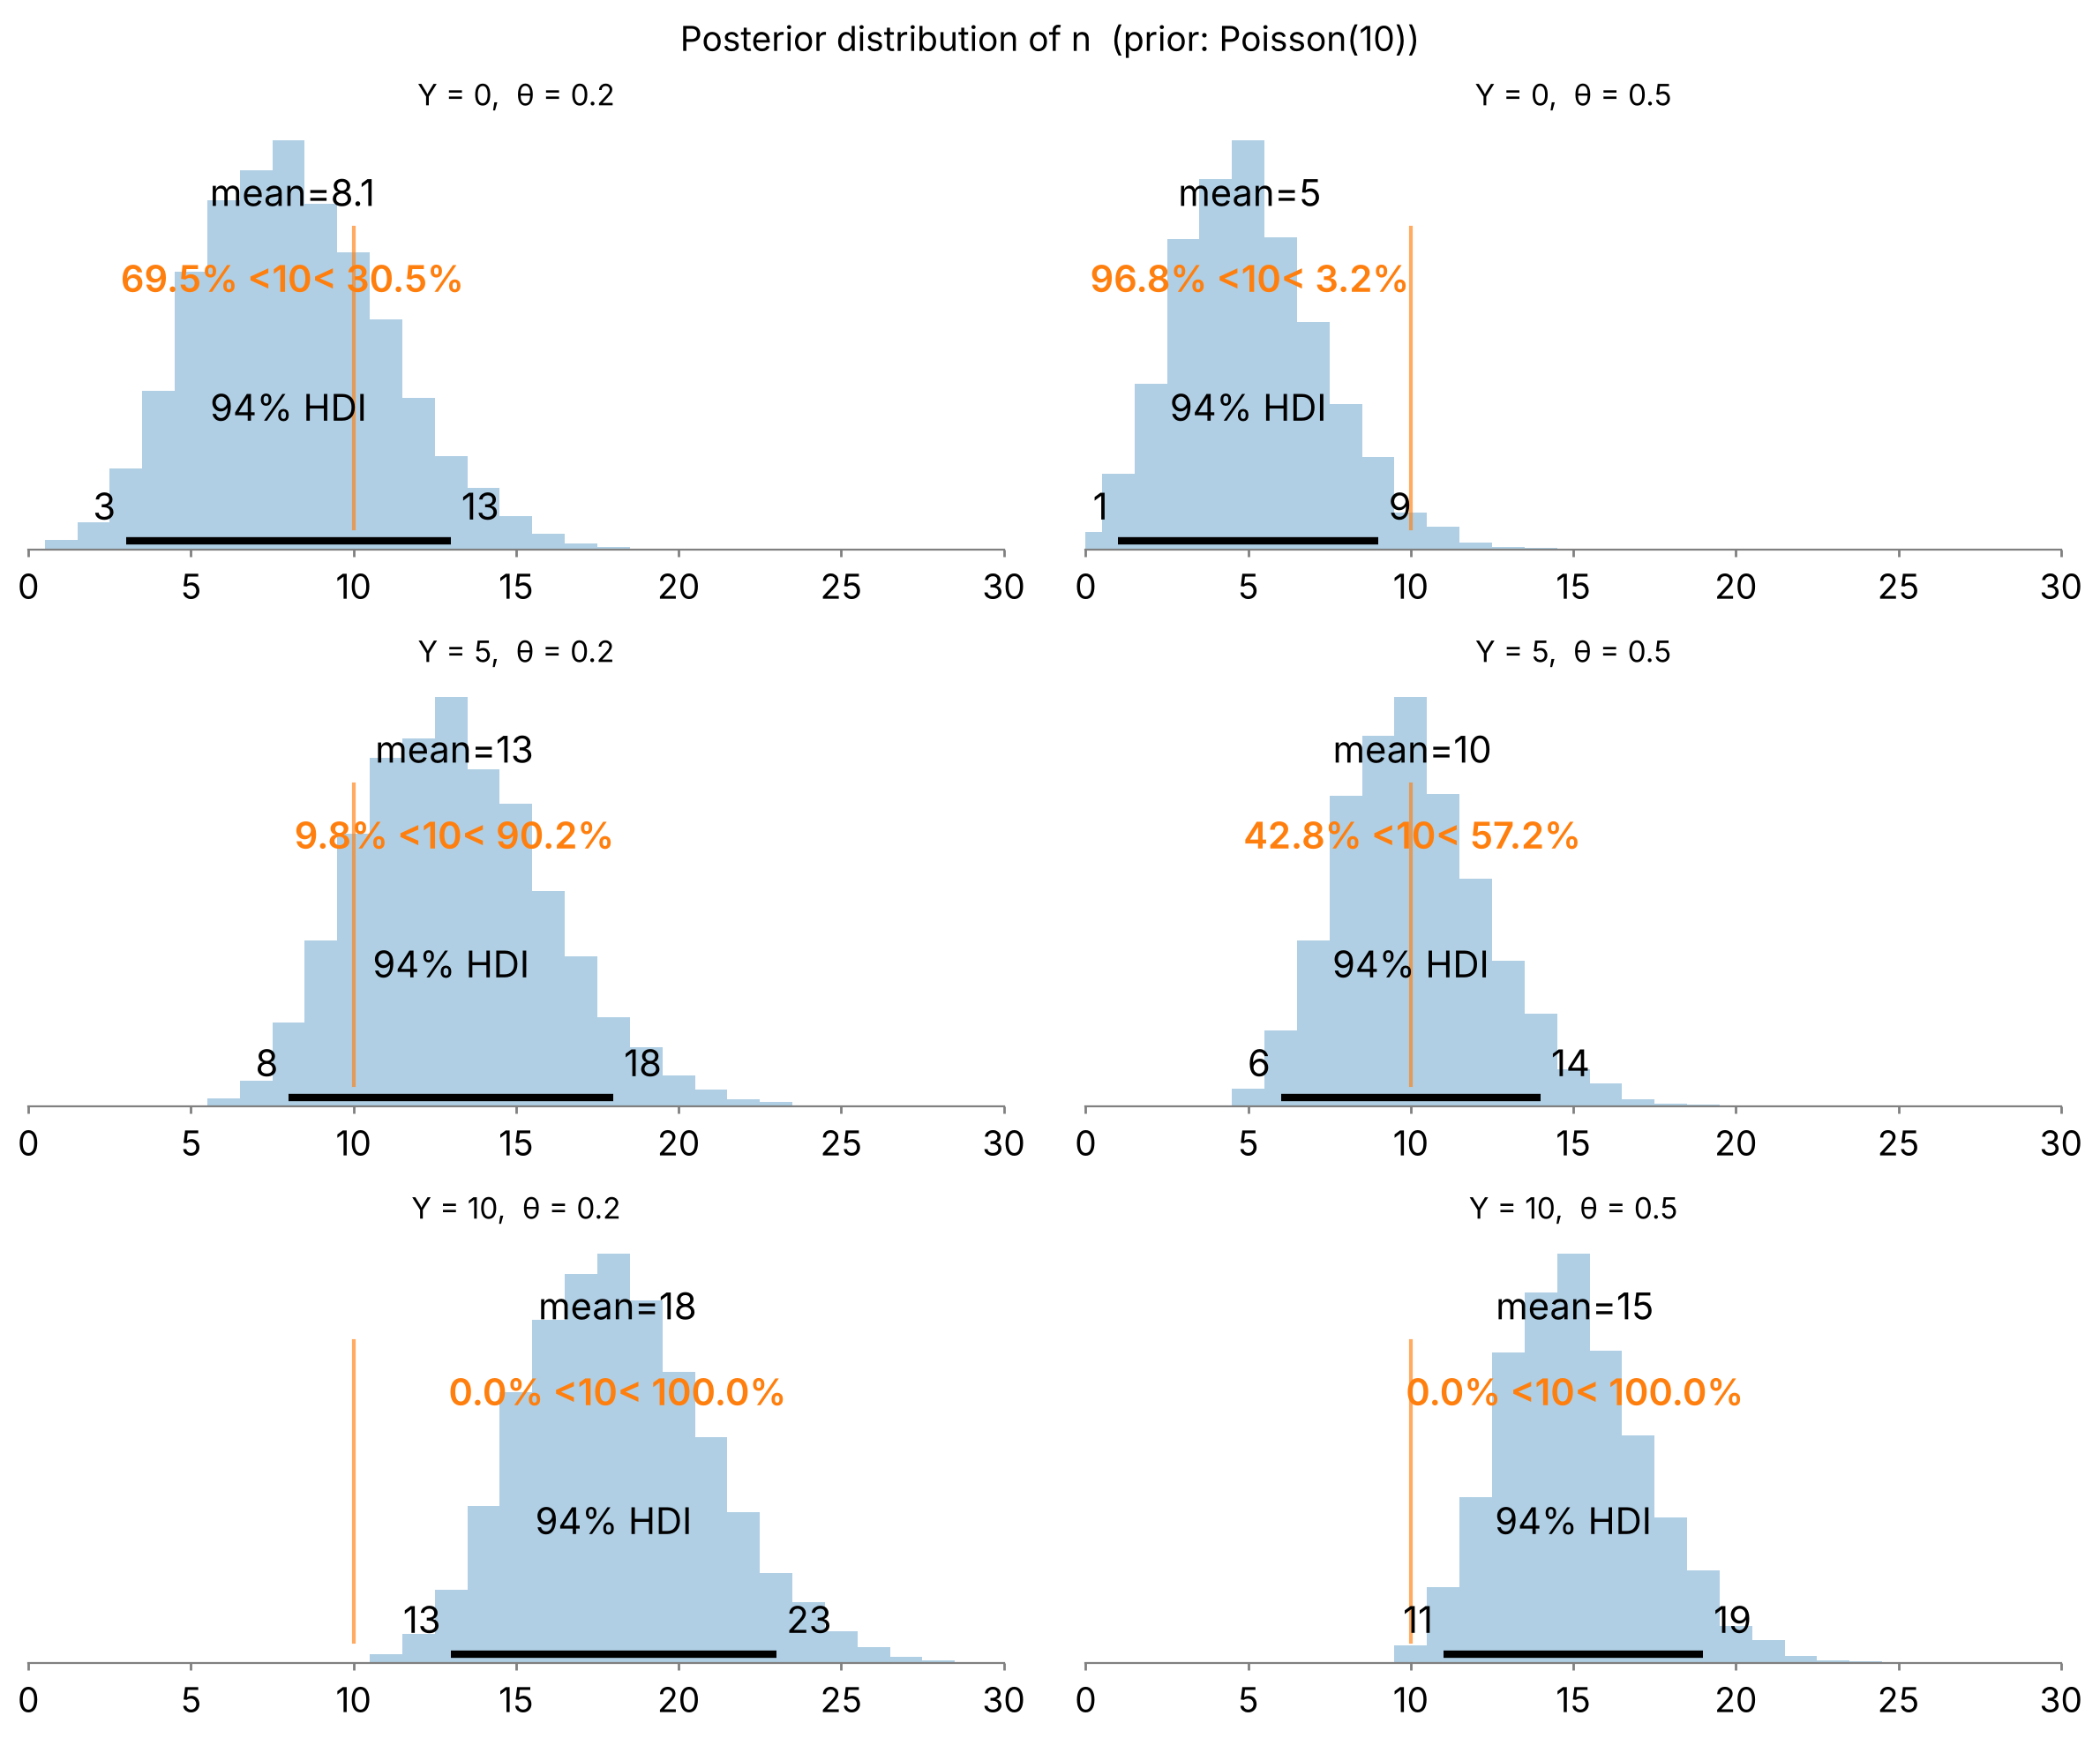

In [3]:
fig, axes = plt.subplots(len(Y_values), len(theta_values), figsize=(12, 10))

for i, Y in enumerate(Y_values):
    for j, theta in enumerate(theta_values):
        az.plot_posterior(results[(Y, theta)], var_names=["n"], ax=axes[i, j],
                          hdi_prob=0.94, ref_val=10, point_estimate="mean")
        axes[i, j].set_title(f"Y = {Y},  θ = {theta}")
        axes[i, j].set_xlim(0, 30)   # same x-range in all panels for easy comparison

fig.suptitle("Posterior distribution of n  (prior: Poisson(10))", fontsize=14)
plt.tight_layout()
plt.show()

## 3. Numerical summary



In [4]:
rows = []
for (Y, theta), idata in results.items():
    s = az.summary(idata, var_names=["n"], hdi_prob=0.94)
    rows.append({"Y": Y, "theta": theta, **s.loc["n", ["mean", "sd", "hdi_3%", "hdi_97%", "r_hat", "ess_bulk"]].to_dict()})
summary = pd.DataFrame(rows)
summary

,Y,theta,mean,sd,hdi_3%,hdi_97%,r_hat,ess_bulk
0,0,0.2,8.118,2.891,3.0,13.0,1.0,3621.0
1,0,0.5,5.046,2.255,1.0,9.0,1.0,3489.0
2,5,0.2,13.101,2.899,8.0,18.0,1.0,3623.0
3,5,0.5,10.046,2.255,6.0,14.0,1.0,3489.0
4,10,0.2,18.120,2.861,13.0,23.0,1.0,3629.0
5,10,0.5,15.045,2.255,11.0,19.0,1.0,3490.0


## 4. Sanity check with the exact posterior

For this model the posterior is known in closed form (Poisson thinning): the customers who did **not** buy, $n - Y$, are independent of $Y$ and follow $\text{Poisson}(10(1-\theta))$. So

$$n \mid Y \;=\; Y + \text{Poisson}\big(10(1-\theta)\big), \qquad E[n \mid Y] = Y + 10(1-\theta), \quad \text{sd} = \sqrt{10(1-\theta)}.$$

We compare these exact values with the PyMC estimates.

In [5]:
summary["exact_mean"] = summary["Y"] + 10 * (1 - summary["theta"])
summary["exact_sd"] = np.sqrt(10 * (1 - summary["theta"]))
summary[["Y", "theta", "mean", "exact_mean", "sd", "exact_sd"]].round(2)

,Y,theta,mean,exact_mean,sd,exact_sd
0,0,0.2,8.12,8.0,2.89,2.83
1,0,0.5,5.05,5.0,2.26,2.24
2,5,0.2,13.10,13.0,2.90,2.83
3,5,0.5,10.05,10.0,2.26,2.24
4,10,0.2,18.12,18.0,2.86,2.83
5,10,0.5,15.04,15.0,2.26,2.24


## 5. Effect of Y and θ on the posterior

**Effect of Y (number of buyers).**
We can never have fewer visitors than buyers, so n is always at least Y.
- If Y is small (Y = 0), we think there were few visitors, so the posterior moves to the left.
- If Y is large (Y = 10), we think there were many visitors, so the posterior moves to the right.

In short, a bigger Y moves the posterior to the right.

**Effect of θ (probability of buying).**
- If θ is small (0.2), most visitors don't buy. Then knowing Y doesn't tell us much about n, so the posterior is wide (we are less sure).
- If θ is bigger (0.5), half of the visitors buy. Then Y tells us a lot about n, so the posterior is narrow (we are more sure).

